# Exploratory Data Analysis — Retail Large Dataset

**Objective:** Univariate, bivariate, and multivariate EDA on the retail transaction dataset. Focus areas: statistical distributions, outlier detection, correlation, skewness/kurtosis, and actionable business insights.

**Structure:** every section follows the pattern — *objective (markdown) → analysis (code) → interpretation (markdown, filled after running)*.

> Note: interpretation cells below are placeholders. They will be filled based on **actual outputs** from this dataset, not the example findings in the project brief (which describe a different dataset and are contradicted by this data in places).

## 1. Setup — Imports & Global Configuration
Load libraries, configure plotting, and define helpers used throughout the notebook.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
# Directory safety
Path('outputs/figures').mkdir(parents=True, exist_ok=True)
Path('data').mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 12

PALETTES = ['husl', 'Set2', 'Set3', 'viridis', 'coolwarm', 'magma', 'pastel']
_state = {'i': 0}

def next_palette():
    p = PALETTES[_state['i'] % len(PALETTES)]
    _state['i'] += 1
    return p

def save_fig(name, dpi=120):
    path = f'outputs/figures/{name}.png'
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f'saved -> {path}')

print('Setup complete.')

Setup complete.


## 2. Load & First Look
Load `data/Original_dataset.csv` and inspect shape, dtypes, and samples. No modifications yet — this is the untouched baseline snapshot.

In [3]:
csv_path = Path('data/Original_dataset.csv')
if not csv_path.exists():
    raise FileNotFoundError(f'Missing dataset at {csv_path.resolve()}. Place Original_dataset.csv under data/ and rerun.')

df = pd.read_csv(csv_path)
print(f'Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')
print(f'Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
df.head()

Rows: 100,000 | Columns: 18
Memory: 68.89 MB


,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,C10000,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,"107,855.82",Debit Card,Standard,5,No
1,C10001,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,"71,878.40",Cash on Delivery,Standard,4,Yes
2,C10002,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,"82,637.46",Credit Card,Standard,5,No
3,C10003,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,"71,411.34",UPI,Standard,3,No
4,C10004,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,"29,365.60",UPI,Standard,2,No


In [4]:
df.tail()

,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
99995,C109995,29,Female,Pune,Maharashtra,Regular,O149995,2024-06-11,Health,Supplements,49293,1,11,"43,870.77",Debit Card,Standard,9,No
99996,C109996,28,Male,Mumbai,Maharashtra,Premium,O149996,2024-04-27,Fashion,Men T-Shirt,5722,2,22,"8,926.32",Cash on Delivery,Express,1,No
99997,C109997,44,Female,Jaipur,Rajasthan,Premium,O149997,2024-04-14,Grocery,Snacks,6311,4,11,"22,467.16",Cash on Delivery,Express,9,No
99998,C109998,45,Male,Jaipur,Rajasthan,Premium,O149998,2024-09-08,Beauty,Shampoo,46888,1,28,"33,759.36",Debit Card,Standard,1,No
99999,C109999,19,Male,Kolkata,West Bengal,New,O149999,2025-11-15,Health,Supplements,37361,3,3,"108,720.51",Credit Card,Standard,2,No


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  str    
 1   age                  100000 non-null  int64  
 2   gender               100000 non-null  str    
 3   city                 100000 non-null  str    
 4   state                100000 non-null  str    
 5   customer_segment     100000 non-null  str    
 6   order_id             100000 non-null  str    
 7   order_date           100000 non-null  str    
 8   product_category     100000 non-null  str    
 9   product_subcategory  100000 non-null  str    
 10  product_price        100000 non-null  int64  
 11  quantity             100000 non-null  int64  
 12  discount_percentage  100000 non-null  int64  
 13  final_price          100000 non-null  float64
 14  payment_method       100000 non-null  str    
 15  shipping_type        100000 n

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"100,000.00",NaN,NaN,NaN,41.56,13.85,18.00,30.00,42.00,54.00,65.00
gender,100000,2,Male,50111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,100000,10,Hyderabad,10150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,100000,9,Maharashtra,19952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,100000,3,New,33488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,100000,100000,O50000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,100000,1095,2023-04-12,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,100000,6,Health,16858,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_subcategory,100000,21,Protein Powder,5668,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Column Audit
Verify column names are clean (no leading/trailing whitespace, no special characters), no duplicates, and dtypes are sensible.

In [7]:
cols = pd.Series(df.columns, name='name')
audit = pd.DataFrame({
    'name': cols,
    'has_space': cols.str.contains(' ', regex=False),
    'has_special': cols.str.contains(r'[^A-Za-z0-9_]', regex=True),
    'leading_trailing_ws': cols.str.strip() != cols,
})
print('Column names audit:')
audit

Column names audit:


,name,has_space,has_special,leading_trailing_ws
0,customer_id,False,False,False
1,age,False,False,False
2,gender,False,False,False
3,city,False,False,False
4,state,False,False,False
5,customer_segment,False,False,False
6,order_id,False,False,False
7,order_date,False,False,False
8,product_category,False,False,False
9,product_subcategory,False,False,False


In [8]:
dup_cols = df.columns[df.columns.duplicated()].tolist()
print(f'Duplicate column names: {dup_cols if dup_cols else "None"}')
print('\nDtype distribution:')
print(df.dtypes.value_counts())

Duplicate column names: None

Dtype distribution:
str        12
int64       5
float64     1
Name: count, dtype: int64


### Interpretation — Column Audit
*TODO: state findings (spaces/special characters/duplicates present or absent; dtype sanity).*

## 4. Preprocessing & Cleaning
Steps: (4.1–4.3) column & string normalisation, date parsing; (4.4–4.5) duplicates & missing values; (4.6–4.7) integrity checks; (4.8) feature engineering; (4.9–4.10) outlier detection + `final_price_capped`; (4.11) save `Processed_dataset.csv`.

In [9]:
df_clean = df.copy()

df_clean.columns = [c.strip() for c in df_clean.columns]

for c in df_clean.select_dtypes(include='object').columns:
    df_clean[c] = df_clean[c].astype(str).str.strip()

df_clean['order_date'] = pd.to_datetime(df_clean['order_date'], errors='coerce')
print(f'Date range: {df_clean["order_date"].min().date()} to {df_clean["order_date"].max().date()}')
print(f'Null dates: {df_clean["order_date"].isna().sum()}')

Date range: 2023-01-01 to 2025-12-30
Null dates: 0


In [10]:
print(f'Full-row duplicates: {df_clean.duplicated().sum()}')
print(f'Duplicate order_ids: {df_clean["order_id"].duplicated().sum()}')

Full-row duplicates: 0
Duplicate order_ids: 0


In [11]:
missing = df_clean.isna().sum().to_frame('nulls')
missing['pct'] = (missing['nulls'] / len(df_clean) * 100).round(2)
missing = missing[missing['nulls'] > 0].sort_values('nulls', ascending=False)
print('No missing values.' if len(missing) == 0 else 'Columns with missing values:')
missing

No missing values.


,nulls,pct


In [12]:
checks = {
    'age_min': df_clean['age'].min(),
    'age_max': df_clean['age'].max(),
    'age_below_18': int((df_clean['age'] < 18).sum()),
    'discount_min': df_clean['discount_percentage'].min(),
    'discount_max': df_clean['discount_percentage'].max(),
    'discount_out_of_0_30': int(((df_clean['discount_percentage'] < 0) | (df_clean['discount_percentage'] > 30)).sum()),
    'quantity_min': df_clean['quantity'].min(),
    'product_price_min': df_clean['product_price'].min(),
    'delivery_days_min': df_clean['delivery_days'].min(),
    'delivery_days_max': df_clean['delivery_days'].max(),
}
expected_fp = df_clean['product_price'] * df_clean['quantity'] * (1 - df_clean['discount_percentage'] / 100)
checks['final_price_mismatches_1e-3'] = int((~np.isclose(expected_fp, df_clean['final_price'], rtol=1e-3)).sum())

for k, v in checks.items():
    print(f'{k:30s}: {v}')

age_min                       : 18
age_max                       : 65
age_below_18                  : 0
discount_min                  : 0
discount_max                  : 30
discount_out_of_0_30          : 0
quantity_min                  : 1
product_price_min             : 500
delivery_days_min             : 1
delivery_days_max             : 10
final_price_mismatches_1e-3   : 0


In [13]:
mapping = df_clean.groupby('product_subcategory')['product_category'].nunique()
inconsistent = mapping[mapping > 1]
print(f'Subcategories mapping to multiple categories: {len(inconsistent)}')
if len(inconsistent):
    print(inconsistent)

Subcategories mapping to multiple categories: 0


In [14]:
df_clean['order_year'] = df_clean['order_date'].dt.year
df_clean['order_month'] = df_clean['order_date'].dt.to_period('M').astype(str)
df_clean['order_weekday'] = df_clean['order_date'].dt.day_name()
df_clean['order_month_name'] = df_clean['order_date'].dt.month_name()

df_clean['revenue_per_unit'] = df_clean['final_price'] / df_clean['quantity']
df_clean['is_return'] = (df_clean['return_status'].str.lower() == 'yes').astype(int)

age_bins = [17, 25, 35, 45, 55, 200]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56+']
df_clean['age_group'] = pd.cut(df_clean['age'], bins=age_bins, labels=age_labels)

df_clean['discount_bin'] = pd.cut(
    df_clean['discount_percentage'],
    bins=[-1, 0, 10, 20, 30],
    labels=['0%', '1-10%', '11-20%', '21-30%']
)

df_clean['delivery_speed'] = pd.cut(
    df_clean['delivery_days'],
    bins=[-1, 3, 7, 100],
    labels=['Fast (<=3d)', 'Medium (4-7d)', 'Slow (>7d)']
)

print(f'df_clean shape: {df_clean.shape}')
df_clean[['order_year','order_month','revenue_per_unit','is_return','age_group','discount_bin','delivery_speed']].head()

df_clean shape: (100000, 27)


,order_year,order_month,revenue_per_unit,is_return,age_group,discount_bin,delivery_speed
0,2025,2025-05,"35,951.94",0,56+,1-10%,Medium (4-7d)
1,2023,2023-11,"17,969.60",1,36-45,11-20%,Medium (4-7d)
2,2025,2025-02,"41,318.73",0,18-25,21-30%,Medium (4-7d)
3,2024,2024-04,"23,803.78",0,36-45,1-10%,Fast (<=3d)
4,2024,2024-10,"29,365.60",0,18-25,1-10%,Fast (<=3d)


In [15]:
num_out_cols = ['age', 'product_price', 'quantity', 'discount_percentage', 'final_price', 'delivery_days']
rows = []
for c in num_out_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_n = int(((df_clean[c] < lo) | (df_clean[c] > hi)).sum())
    z = np.abs(stats.zscore(df_clean[c], nan_policy='omit'))
    z_n = int((z > 3).sum())
    rows.append({'column': c, 'IQR_outliers': iqr_n, 'Z_outliers(>3)': z_n,
                 'fence_low': round(lo, 2), 'fence_high': round(hi, 2)})

pd.DataFrame(rows)

,column,IQR_outliers,Z_outliers(>3),fence_low,fence_high
0,age,0,0,-6.00,90.00
1,product_price,0,0,"-28,998.00","89,330.00"
2,quantity,0,0,-3.50,8.50
3,discount_percentage,0,0,-17.00,47.00
4,final_price,1335,503,"-79,306.60","198,057.67"
5,delivery_days,0,0,-4.50,15.50


In [16]:
q1, q3 = df_clean['final_price'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df_clean['final_price_capped'] = df_clean['final_price'].clip(lower=lo, upper=hi)
n_capped = int((df_clean['final_price'] != df_clean['final_price_capped']).sum())
print(f'Capped rows: {n_capped:,} ({n_capped / len(df_clean) * 100:.2f}%)')
print(f'IQR fences: {lo:,.2f} .. {hi:,.2f}')

Capped rows: 1,335 (1.33%)
IQR fences: -79,306.60 .. 198,057.67


In [17]:
df_clean.to_csv('data/Processed_dataset.csv', index=False)
print('Saved -> data/Processed_dataset.csv')
print(f'Final shape: {df_clean.shape}')

Saved -> data/Processed_dataset.csv
Final shape: (100000, 28)


### Interpretation — Preprocessing
*TODO: describe what was cleaned, duplicates/missing counts, integrity check outcomes, number of capped rows, and confirm `df_clean` ready.*

## 5. Univariate — Numerical Variables
Central tendency, dispersion, **skewness**, **kurtosis**, and distribution shape. Uses the raw `final_price` so extreme values remain visible.

In [18]:
num_cols = ['age', 'product_price', 'quantity', 'discount_percentage',
            'final_price', 'revenue_per_unit', 'delivery_days']

stats_table = pd.DataFrame({
    'mean':     [df_clean[c].mean() for c in num_cols],
    'median':   [df_clean[c].median() for c in num_cols],
    'std':      [df_clean[c].std() for c in num_cols],
    'min':      [df_clean[c].min() for c in num_cols],
    'max':      [df_clean[c].max() for c in num_cols],
    'skew':     [df_clean[c].skew() for c in num_cols],
    'kurtosis': [df_clean[c].kurtosis() for c in num_cols],
}, index=num_cols).round(3)
stats_table

,mean,median,std,min,max,skew,kurtosis
age,41.56,42.00,13.85,18.00,65.00,-0.01,-1.20
product_price,"30,164.53","30,148.00","17,139.68",500.00,"59,998.00",0.00,-1.20
quantity,2.50,3.00,1.12,1.00,4.00,-0.00,-1.36
discount_percentage,15.01,15.00,8.95,0.00,30.00,-0.00,-1.20
final_price,"64,165.72","49,752.39","49,969.28",357.00,"239,980.00",0.94,0.17
revenue_per_unit,"25,641.29","25,356.06","14,903.12",357.00,"59,995.00",0.11,-1.04
delivery_days,5.51,5.00,2.87,1.00,10.00,0.00,-1.22


saved -> outputs/figures/univariate_numeric_histograms.png


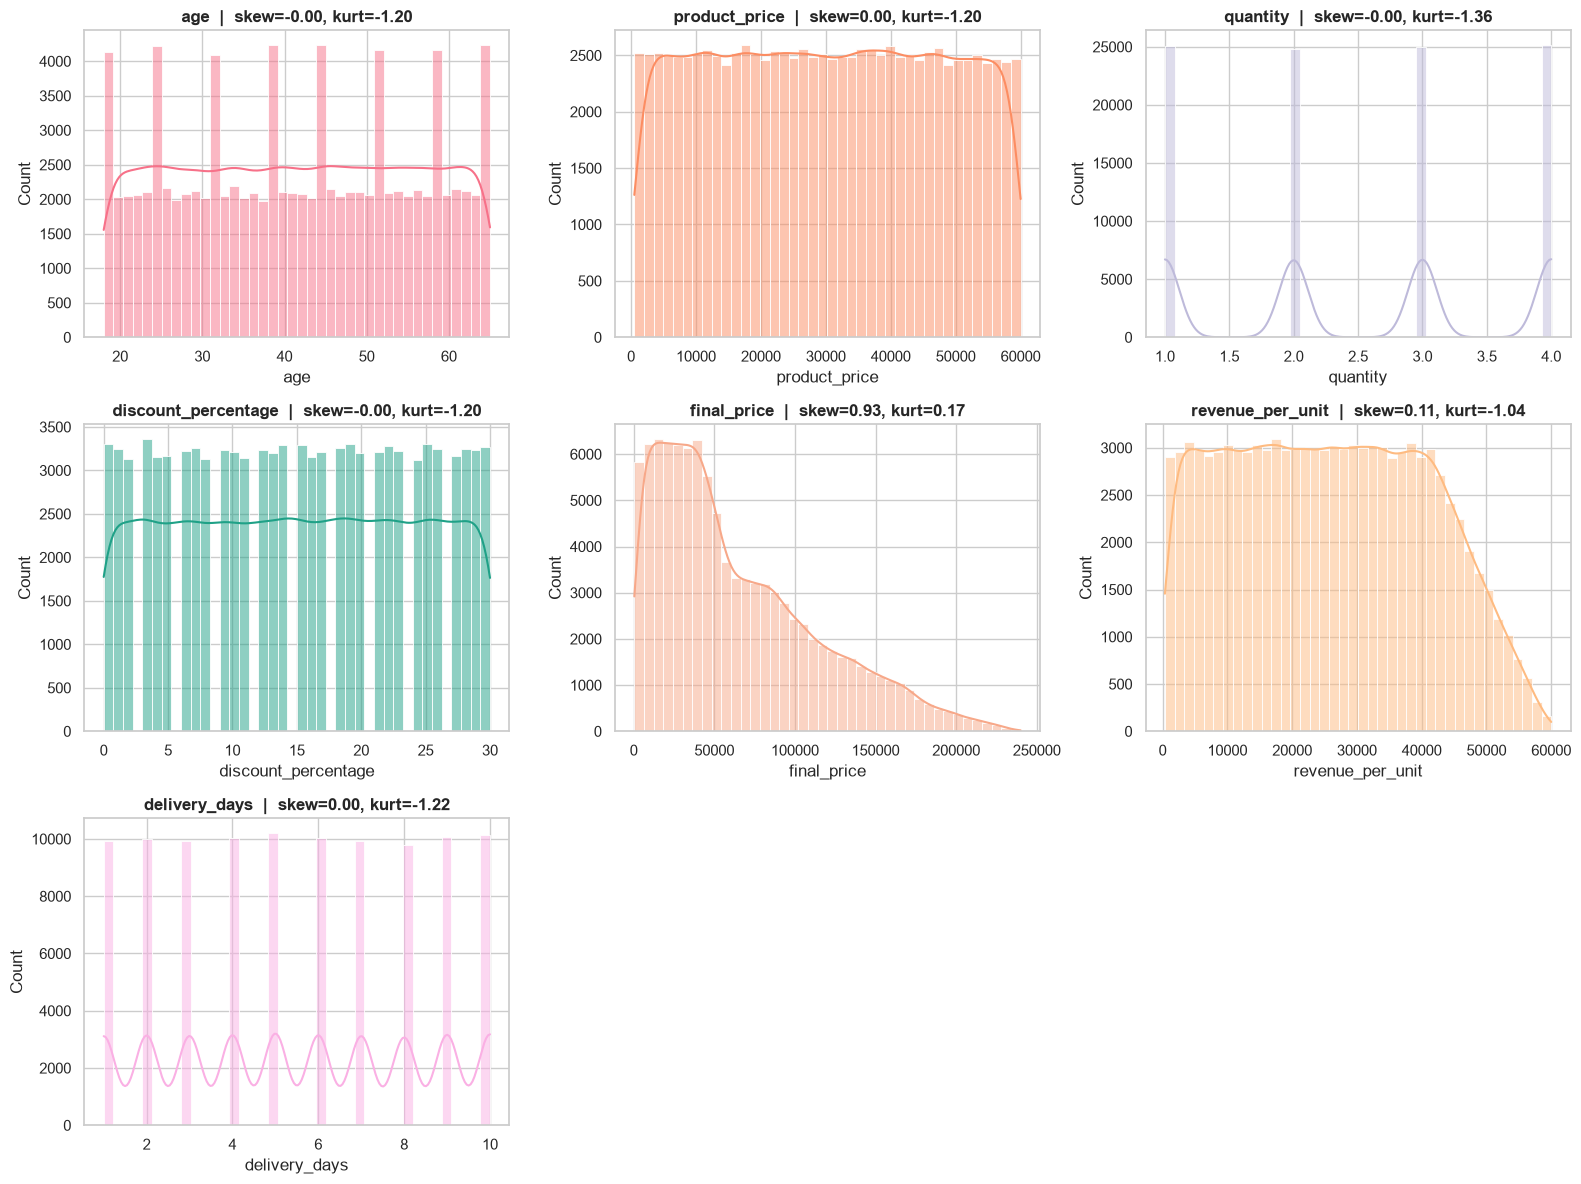

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    pal = sns.color_palette(next_palette())
    sns.histplot(df_clean[c], kde=True, ax=axes[i], color=pal[i % len(pal)], bins=40)
    axes[i].set_title(f'{c}  |  skew={df_clean[c].skew():.2f}, kurt={df_clean[c].kurtosis():.2f}')
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
save_fig('univariate_numeric_histograms')
plt.show()

saved -> outputs/figures/univariate_numeric_boxplots.png


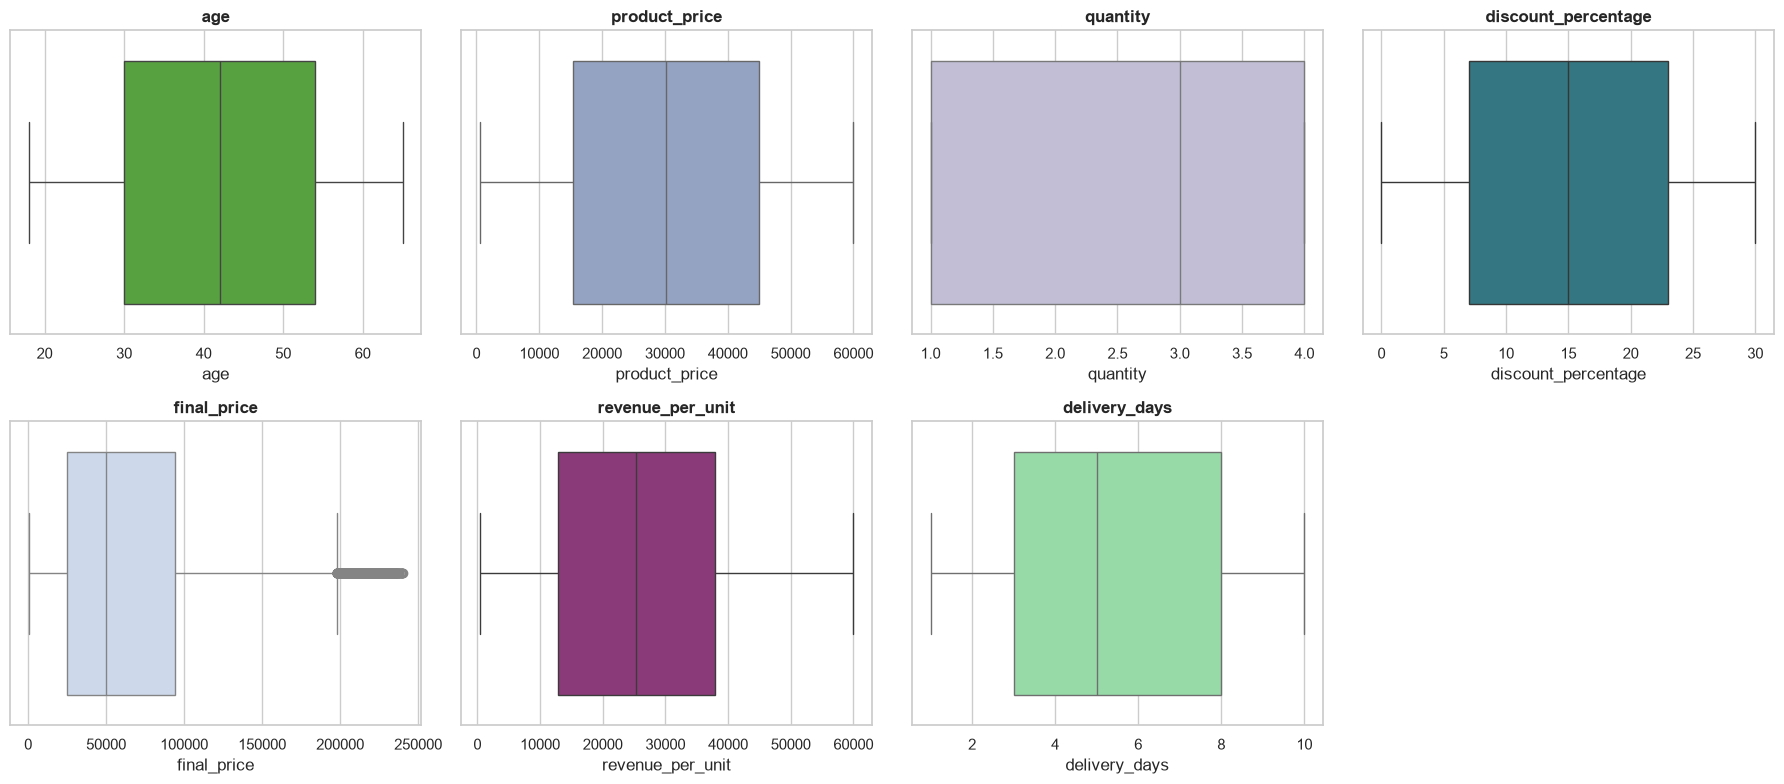

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    pal = sns.color_palette(next_palette())
    sns.boxplot(x=df_clean[c], ax=axes[i], color=pal[2])
    axes[i].set_title(c)
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
save_fig('univariate_numeric_boxplots')
plt.show()

saved -> outputs/figures/univariate_numeric_violins.png


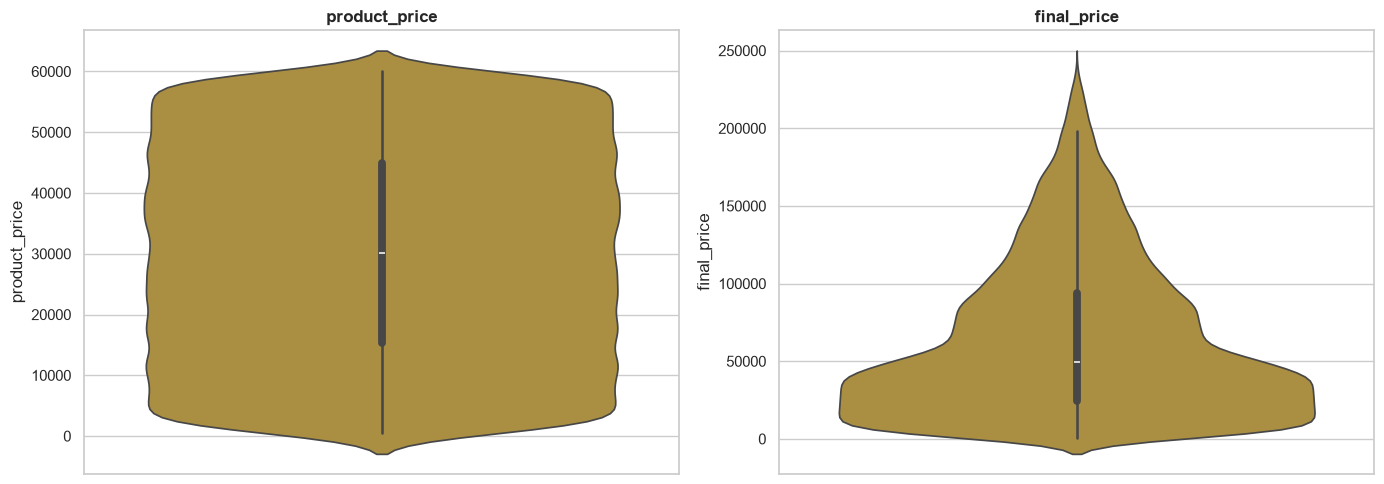

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pal = sns.color_palette(next_palette())
sns.violinplot(y=df_clean['product_price'], ax=axes[0], color=pal[1])
axes[0].set_title('product_price')
sns.violinplot(y=df_clean['final_price'], ax=axes[1], color=pal[1])
axes[1].set_title('final_price')
plt.tight_layout()
save_fig('univariate_numeric_violins')
plt.show()

### Interpretation — Univariate Numerical
*TODO: which columns are right-skewed, where kurtosis indicates heavy tails, whether PDF claims hold on this data.*

## 6. Univariate — Categorical Variables
Frequency distributions and dominance/rarity checks. Return rate is calculated explicitly.

In [22]:
cat_cols = ['gender', 'city', 'state', 'customer_segment', 'product_category',
            'product_subcategory', 'payment_method', 'shipping_type', 'return_status']

for c in cat_cols:
    print(f'\n--- {c} ---')
    print(df_clean[c].value_counts().head(10))


--- gender ---
gender
Male      50111
Female    49889
Name: count, dtype: int64

--- city ---
city
Hyderabad    10150
Ahmedabad    10057
Bangalore    10047
Mumbai       10015
Chennai       9993
Noida         9964
Delhi         9962
Kolkata       9955
Pune          9937
Jaipur        9920
Name: count, dtype: int64

--- state ---
state
Maharashtra      19952
Telangana        10150
Gujarat          10057
Karnataka        10047
Tamil Nadu        9993
Uttar Pradesh     9964
Delhi             9962
West Bengal       9955
Rajasthan         9920
Name: count, dtype: int64

--- customer_segment ---
customer_segment
New        33488
Regular    33361
Premium    33151
Name: count, dtype: int64

--- product_category ---
product_category
Health            16858
Home & Kitchen    16848
Fashion           16613
Grocery           16592
Electronics       16576
Beauty            16513
Name: count, dtype: int64

--- product_subcategory ---
product_subcategory
Protein Powder    5668
Supplements       5657
Sh

saved -> outputs/figures/univariate_categorical_counts.png


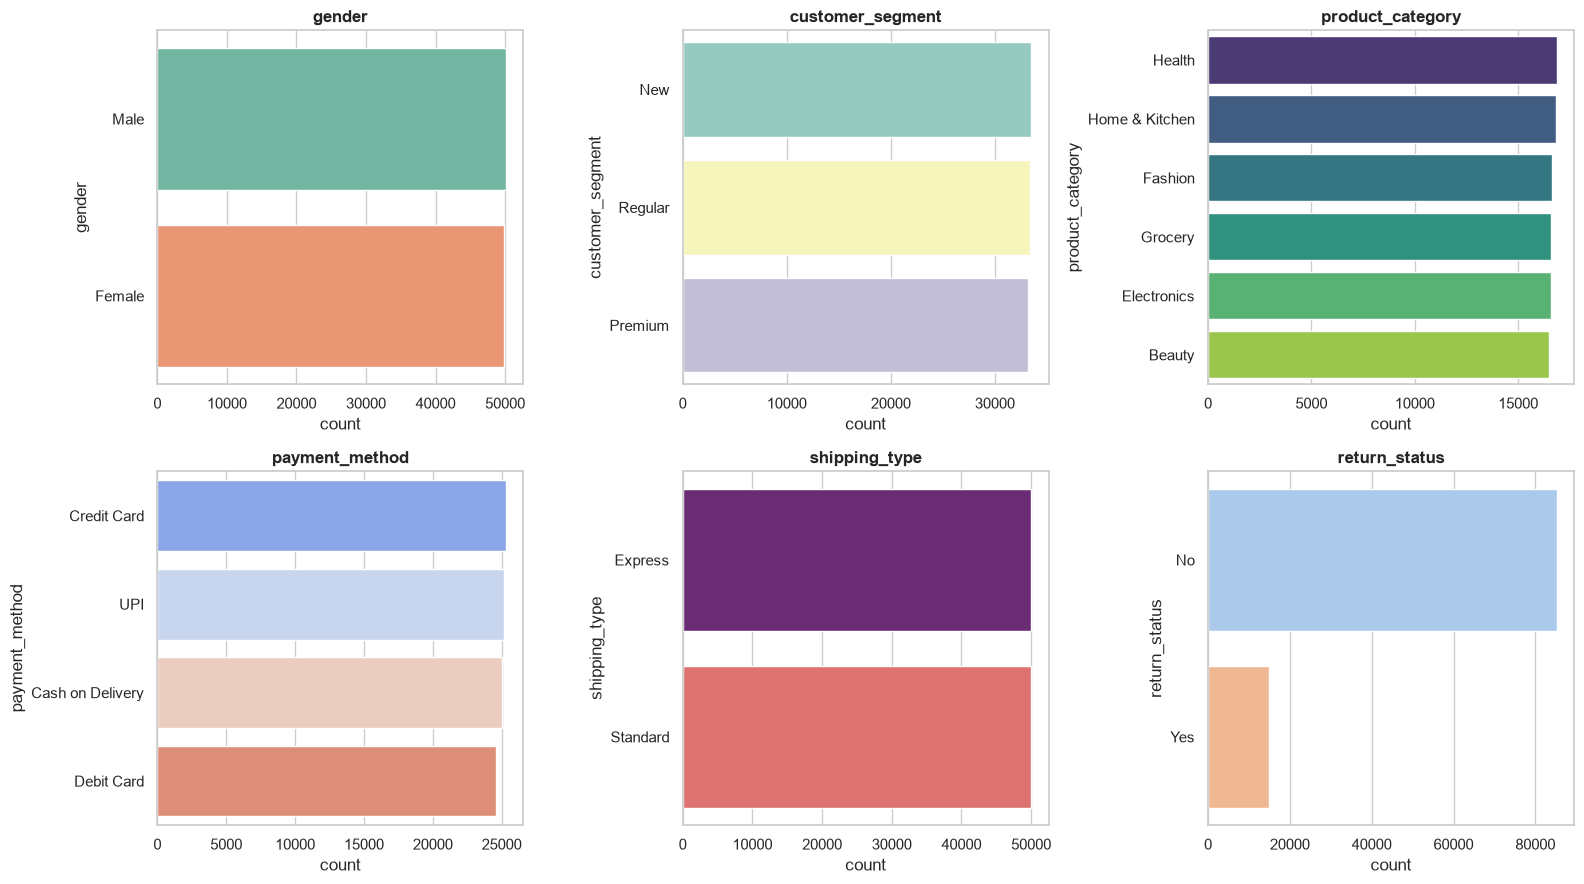

In [23]:
plot_cats = ['gender', 'customer_segment', 'product_category', 'payment_method', 'shipping_type', 'return_status']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, c in enumerate(plot_cats):
    sns.countplot(data=df_clean, y=c, ax=axes[i],
                  palette=next_palette(),
                  order=df_clean[c].value_counts().index)
    axes[i].set_title(c)
plt.tight_layout()
save_fig('univariate_categorical_counts')
plt.show()

In [24]:
ret_rate = df_clean['is_return'].mean() * 100
print(f'Overall return rate: {ret_rate:.2f}%')
print(f'Total transactions: {len(df_clean):,}')
print(f'Total returns: {df_clean["is_return"].sum():,}')

Overall return rate: 14.81%
Total transactions: 100,000
Total returns: 14,811


### Interpretation — Univariate Categorical
*TODO: dominant categories and whether the PDF's ~15% return rate holds.*

## 7. Bivariate — Numerical vs Numerical
Scatter + regression, Pearson + Spearman, and point-biserial for delivery_days vs is_return.

saved -> outputs/figures/bivariate_numeric_scatter.png


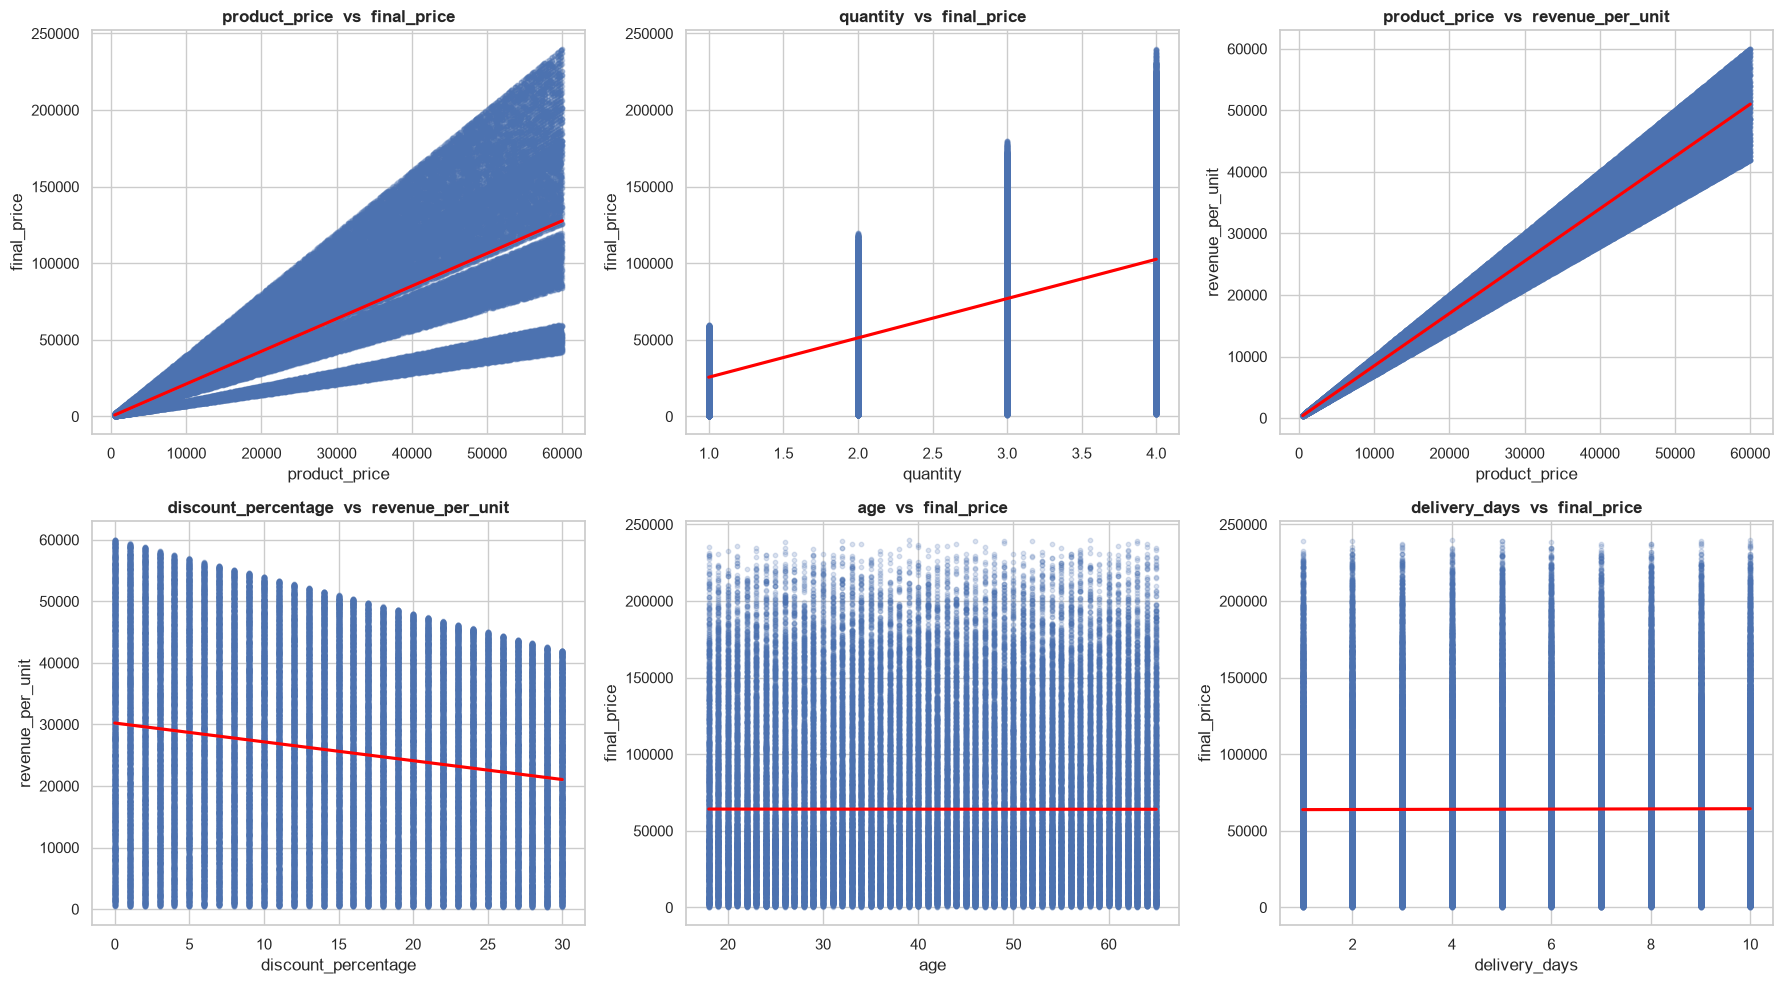

In [25]:
pairs = [('product_price', 'final_price'),
         ('quantity', 'final_price'),
         ('product_price', 'revenue_per_unit'),
         ('discount_percentage', 'revenue_per_unit'),
         ('age', 'final_price'),
         ('delivery_days', 'final_price')]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, (a, b) in enumerate(pairs):
    sns.regplot(data=df_clean, x=a, y=b, ax=axes[i],
                scatter_kws={'alpha': 0.2, 's': 10},
                line_kws={'color': 'red'})
    axes[i].set_title(f'{a}  vs  {b}')
plt.tight_layout()
save_fig('bivariate_numeric_scatter')
plt.show()

In [26]:
rows = []
for a, b in pairs:
    pear = df_clean[[a, b]].corr(method='pearson').iloc[0, 1]
    spear = df_clean[[a, b]].corr(method='spearman').iloc[0, 1]
    rows.append({'pair': f'{a} vs {b}', 'pearson': round(pear, 3), 'spearman': round(spear, 3)})
pd.DataFrame(rows)

,pair,pearson,spearman
0,product_price vs final_price,0.73,0.78
1,quantity vs final_price,0.57,0.55
2,product_price vs revenue_per_unit,0.98,0.98
3,discount_percentage vs revenue_per_unit,-0.18,-0.17
4,age vs final_price,-0.00,0.00
5,delivery_days vs final_price,0.00,0.00


In [27]:
from scipy.stats import pointbiserialr
r, p = pointbiserialr(df_clean['is_return'], df_clean['delivery_days'])
print(f'Point-biserial r (delivery_days vs is_return) = {r:.3f}, p = {p:.4g}')

Point-biserial r (delivery_days vs is_return) = 0.001, p = 0.8685


### Interpretation — Numerical vs Numerical
*TODO: verify or contradict PDF claims; note if Spearman diverges from Pearson.*

## 8. Bivariate — Numerical vs Categorical
Boxplots + mean/median tables (raw and capped), backed by ANOVA and Kruskal–Wallis. Welch t-test for delivery_days by shipping type.

saved -> outputs/figures/bivariate_num_vs_cat_boxplots.png


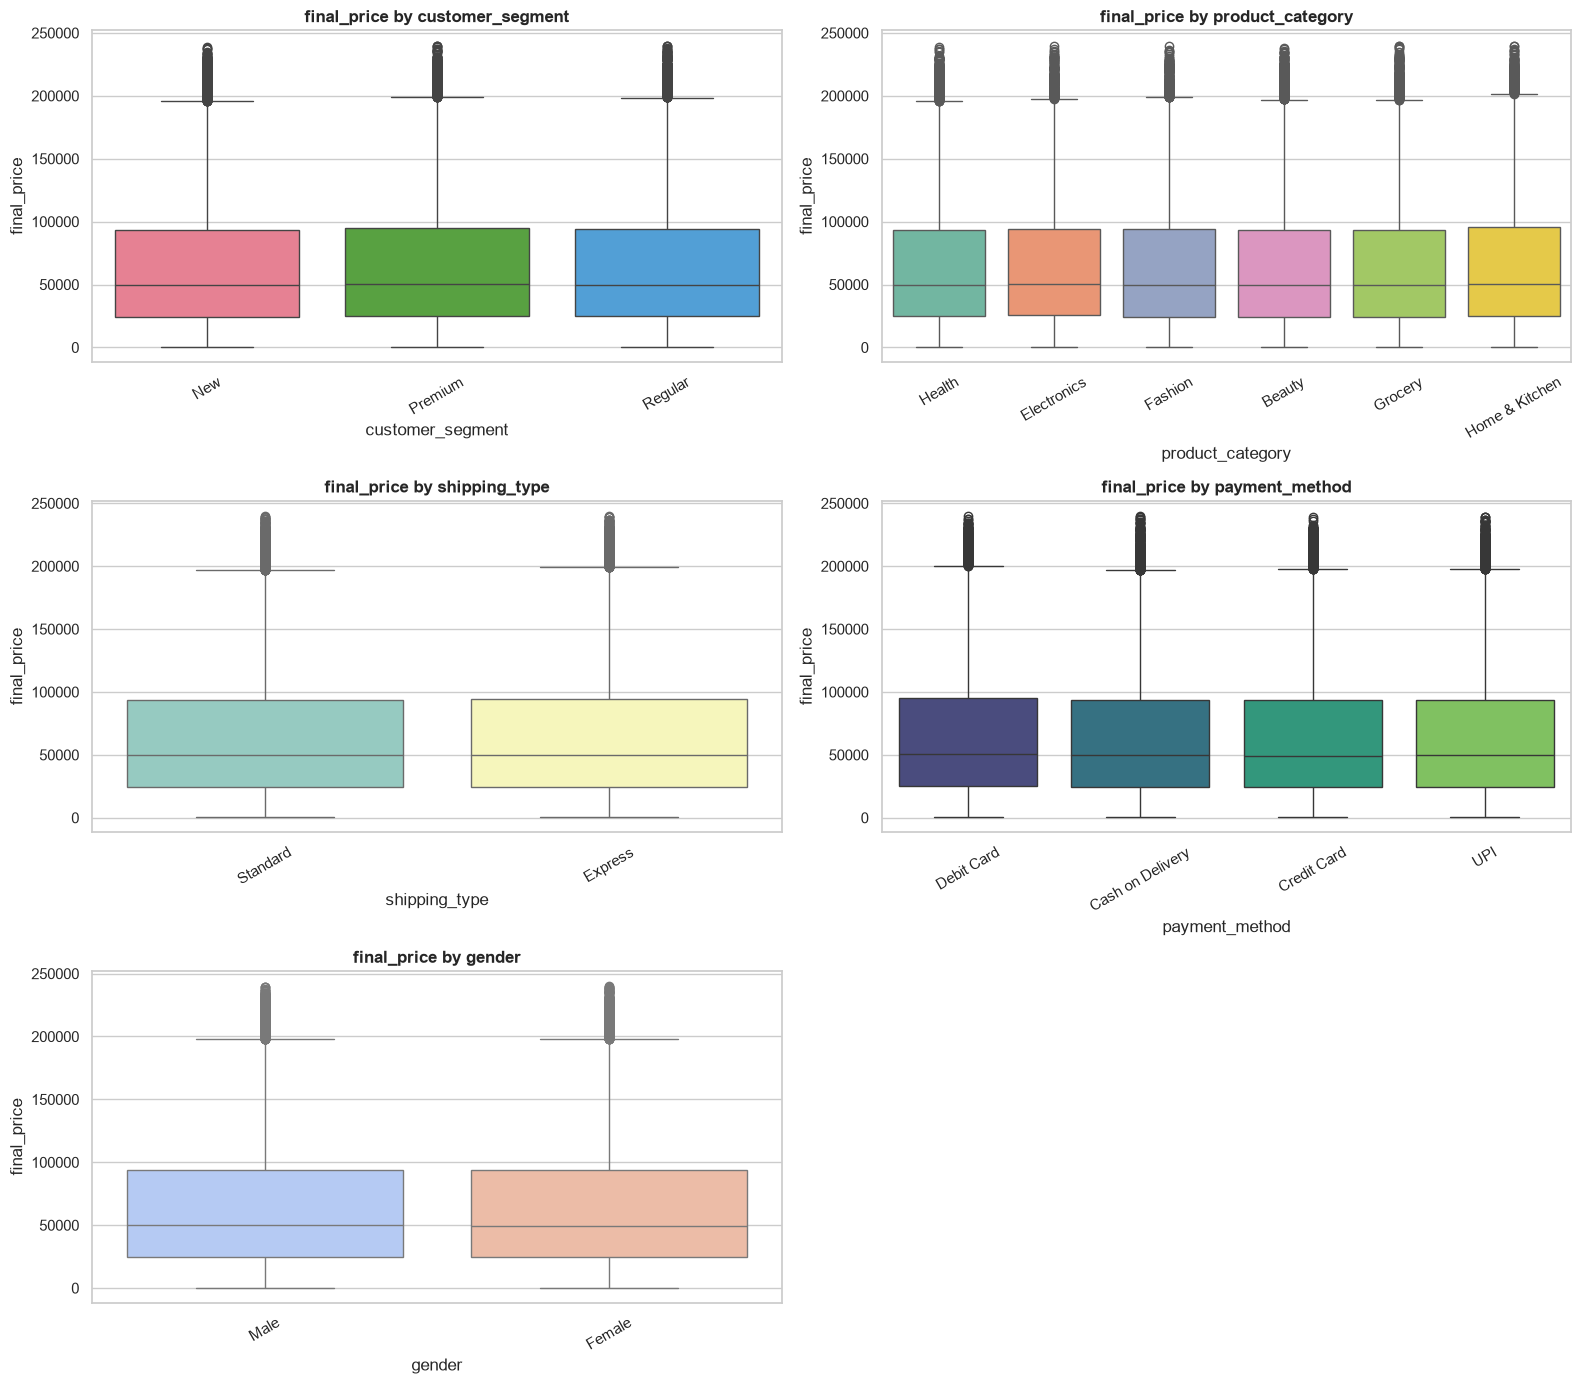

In [28]:
group_cols = ['customer_segment', 'product_category', 'shipping_type', 'payment_method', 'gender']

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()
for i, c in enumerate(group_cols):
    sns.boxplot(data=df_clean, x=c, y='final_price', ax=axes[i], palette=next_palette())
    axes[i].set_title(f'final_price by {c}')
    axes[i].tick_params(axis='x', rotation=30)
axes[-1].axis('off')
plt.tight_layout()
save_fig('bivariate_num_vs_cat_boxplots')
plt.show()

In [29]:
agg = df_clean.groupby('customer_segment').agg(
    mean_spend_raw=('final_price', 'mean'),
    median_spend=('final_price', 'median'),
    mean_spend_capped=('final_price_capped', 'mean'),
    n=('final_price', 'size')
).round(2)
agg

,mean_spend_raw,median_spend,mean_spend_capped,n
customer_segment,,,,
New,"63,766.75","49,224.52","63,584.86",33488
Premium,"64,430.45","50,273.88","64,243.79",33151
Regular,"64,303.15","49,767.84","64,111.04",33361


In [30]:
groups = [g['final_price'].dropna().values for _, g in df_clean.groupby('customer_segment')]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
print(f'ANOVA:          F = {f_stat:.3f}, p = {p_anova:.4g}')
print(f'Kruskal-Wallis: H = {h_stat:.3f}, p = {p_kw:.4g}')

ANOVA:          F = 1.659, p = 0.1904
Kruskal-Wallis: H = 3.913, p = 0.1414


In [31]:
exp = df_clean.loc[df_clean['shipping_type'] == 'Express', 'delivery_days'].dropna()
std = df_clean.loc[df_clean['shipping_type'] == 'Standard', 'delivery_days'].dropna()
t, p = stats.ttest_ind(exp, std, equal_var=False)
print(f'Express  mean = {exp.mean():.2f} (n={len(exp):,})')
print(f'Standard mean = {std.mean():.2f} (n={len(std):,})')
print(f'Welch t-test: t = {t:.3f}, p = {p:.4g}')

Express  mean = 5.50 (n=50,008)
Standard mean = 5.51 (n=49,992)
Welch t-test: t = -0.896, p = 0.3702


### Interpretation — Numerical vs Categorical
*TODO: do segments differ significantly? Does Express actually reduce delivery days?*

## 9. Bivariate — Categorical vs Categorical
Crosstabs with chi-square, plus a return-rate heatmap by category × shipping type.

In [32]:
cross_pairs = [
    ('product_category', 'return_status'),
    ('shipping_type', 'return_status'),
    ('payment_method', 'return_status'),
    ('customer_segment', 'return_status'),
]
for a, b in cross_pairs:
    ct = pd.crosstab(df_clean[a], df_clean[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f'{a} × {b}: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4g}')

product_category × return_status: chi2 = 2.41, dof = 5, p = 0.7906
shipping_type × return_status: chi2 = 0.79, dof = 1, p = 0.3751


payment_method × return_status: chi2 = 1.84, dof = 3, p = 0.6069
customer_segment × return_status: chi2 = 0.52, dof = 2, p = 0.7704


saved -> outputs/figures/return_rate_category_shipping.png


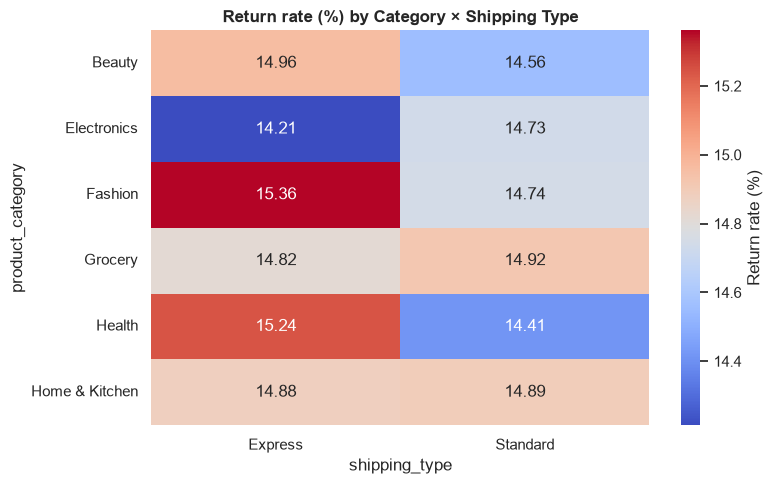

In [33]:
pivot_rs = df_clean.pivot_table(values='is_return', index='product_category',
                                columns='shipping_type', aggfunc='mean') * 100
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_rs, annot=True, fmt='.2f', cmap='coolwarm',
            cbar_kws={'label': 'Return rate (%)'})
plt.title('Return rate (%) by Category × Shipping Type')
plt.tight_layout()
save_fig('return_rate_category_shipping')
plt.show()

saved -> outputs/figures/return_rate_by_category_payment.png


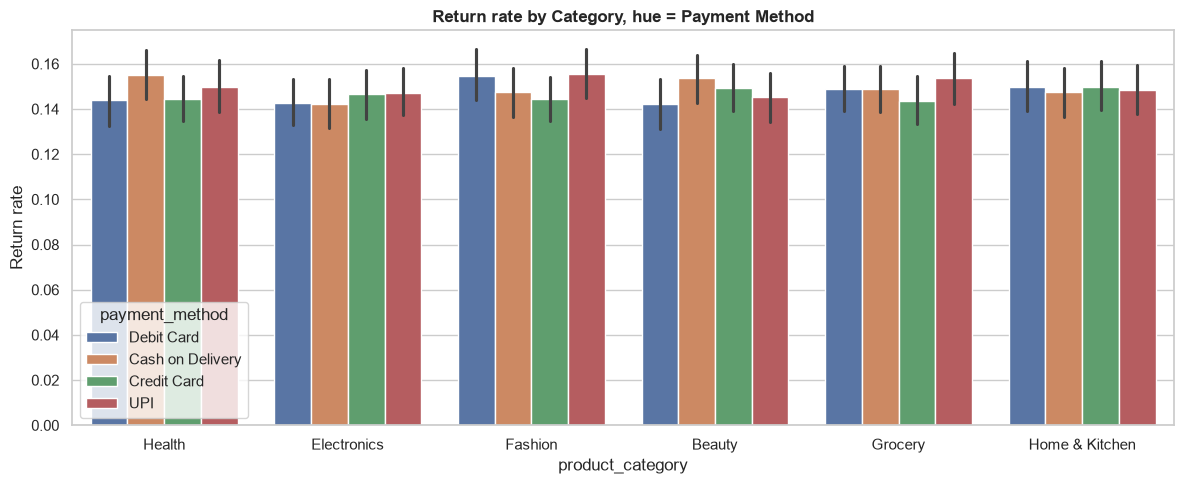

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=df_clean, x='product_category', y='is_return',
            hue='payment_method', ax=ax)
ax.set_ylabel('Return rate')
ax.set_title('Return rate by Category, hue = Payment Method')
plt.tight_layout()
save_fig('return_rate_by_category_payment')
plt.show()

### Interpretation — Categorical vs Categorical
*TODO: which pairs are dependent (low p), Electronics return rate, shipping vs returns.*

## 10. Multivariate Analysis
Full Pearson + Spearman heatmaps; three assignment interactions; pairplot + FacetGrid; VIF.

saved -> outputs/figures/corr_heatmap_pearson.png


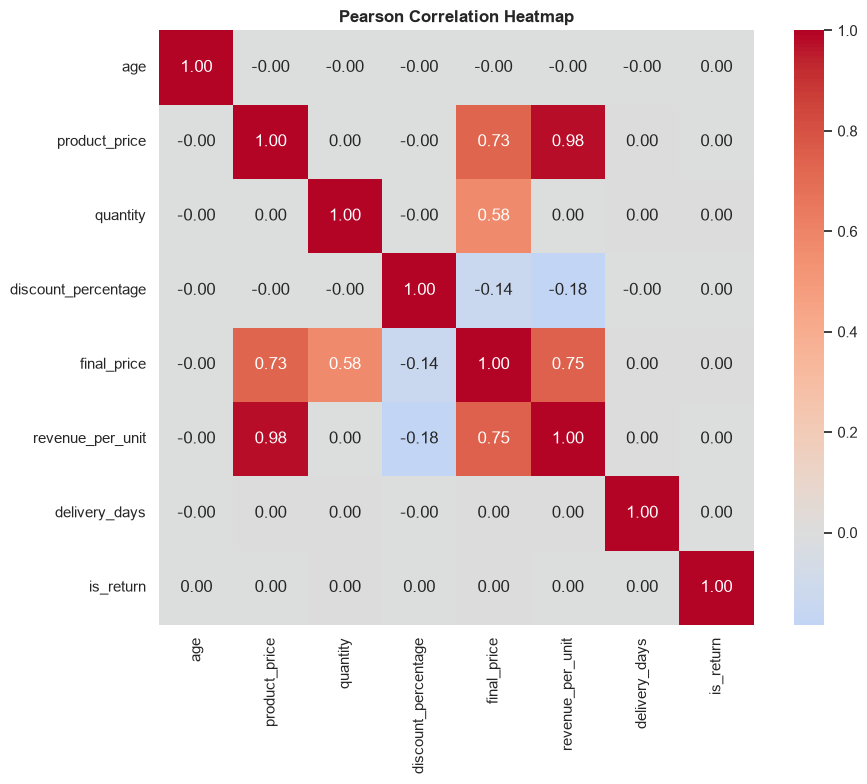

In [35]:
num_for_corr = ['age', 'product_price', 'quantity', 'discount_percentage',
                'final_price', 'revenue_per_unit', 'delivery_days', 'is_return']
pear_corr = df_clean[num_for_corr].corr(method='pearson')
plt.figure(figsize=(10, 8))
sns.heatmap(pear_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
save_fig('corr_heatmap_pearson')
plt.show()

saved -> outputs/figures/corr_heatmap_spearman.png


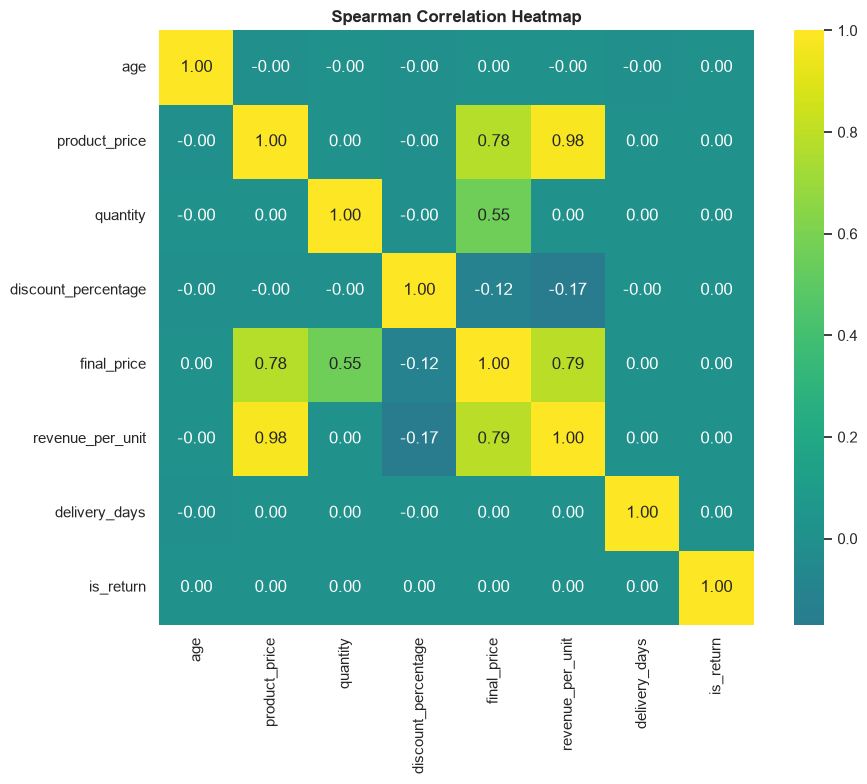

In [36]:
spear_corr = df_clean[num_for_corr].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(spear_corr, annot=True, fmt='.2f', cmap='viridis', center=0, square=True)
plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
save_fig('corr_heatmap_spearman')
plt.show()

saved -> outputs/figures/interaction_category_discount.png


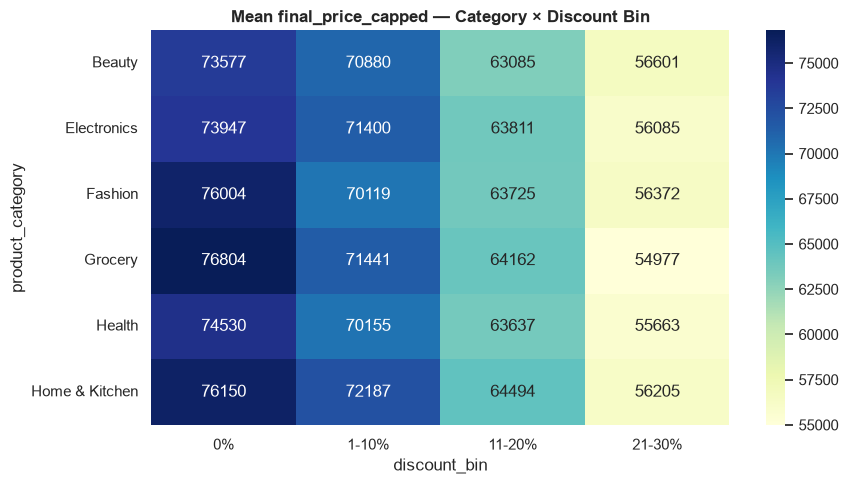

In [37]:
p1 = df_clean.pivot_table(values='final_price_capped', index='product_category',
                          columns='discount_bin', aggfunc='mean')
plt.figure(figsize=(9, 5))
sns.heatmap(p1, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Mean final_price_capped — Category × Discount Bin')
plt.tight_layout()
save_fig('interaction_category_discount')
plt.show()

saved -> outputs/figures/interaction_segment_age.png


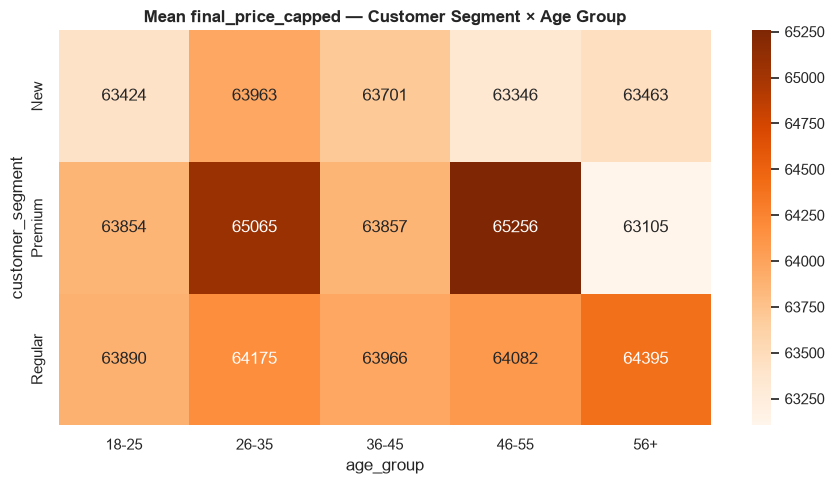

In [38]:
p2 = df_clean.pivot_table(values='final_price_capped', index='customer_segment',
                          columns='age_group', aggfunc='mean')
plt.figure(figsize=(9, 5))
sns.heatmap(p2, annot=True, fmt='.0f', cmap='Oranges')
plt.title('Mean final_price_capped — Customer Segment × Age Group')
plt.tight_layout()
save_fig('interaction_segment_age')
plt.show()

saved -> outputs/figures/interaction_shipping_delivery_returns.png


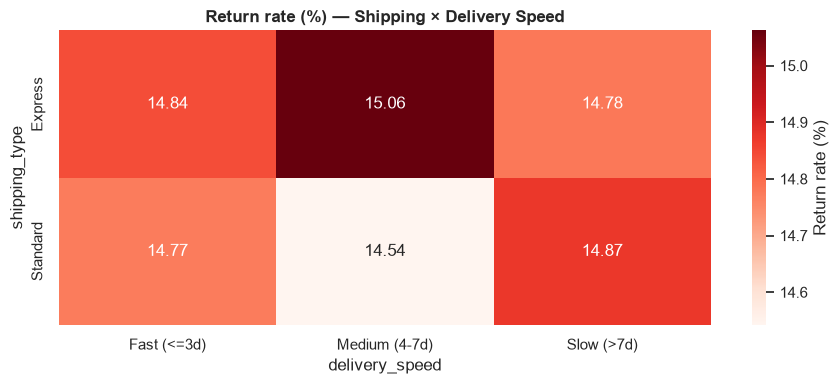

In [39]:
p3 = df_clean.pivot_table(values='is_return', index='shipping_type',
                          columns='delivery_speed', aggfunc='mean') * 100
plt.figure(figsize=(9, 4))
sns.heatmap(p3, annot=True, fmt='.2f', cmap='Reds', cbar_kws={'label': 'Return rate (%)'})
plt.title('Return rate (%) — Shipping × Delivery Speed')
plt.tight_layout()
save_fig('interaction_shipping_delivery_returns')
plt.show()

saved -> outputs/figures/pairplot_numeric_by_segment.png


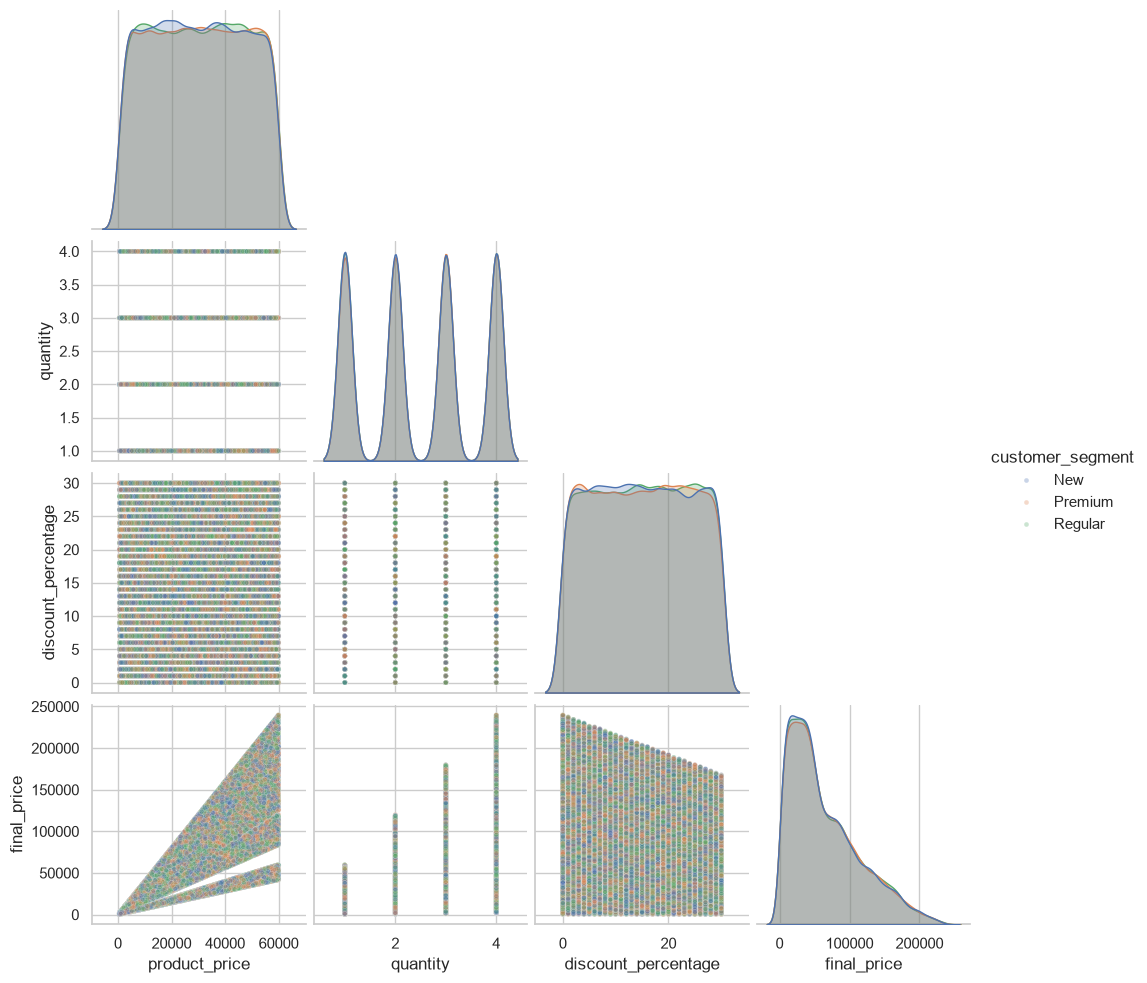

In [40]:
subset = ['product_price', 'quantity', 'discount_percentage', 'final_price', 'customer_segment']
g = sns.pairplot(df_clean[subset], hue='customer_segment', corner=True,
                 plot_kws={'alpha': 0.3, 's': 12})
g.savefig('outputs/figures/pairplot_numeric_by_segment.png', dpi=100, bbox_inches='tight')
print('saved -> outputs/figures/pairplot_numeric_by_segment.png')
plt.show()

saved -> outputs/figures/facetgrid_segment_quantity_price.png


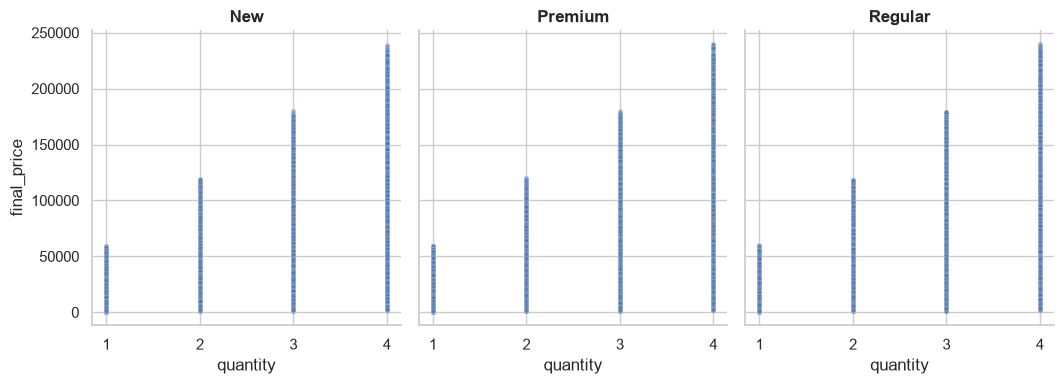

In [41]:
g = sns.FacetGrid(df_clean, col='customer_segment', col_wrap=3, height=4, aspect=0.9)
g.map_dataframe(sns.scatterplot, x='quantity', y='final_price', alpha=0.3, s=12)
g.set_axis_labels('quantity', 'final_price')
g.set_titles(col_template='{col_name}')
g.savefig('outputs/figures/facetgrid_segment_quantity_price.png', dpi=120, bbox_inches='tight')
print('saved -> outputs/figures/facetgrid_segment_quantity_price.png')
plt.show()

In [42]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_cols = ['age', 'product_price', 'quantity', 'discount_percentage', 'delivery_days']
X = df_clean[vif_cols].dropna()
vif_df = pd.DataFrame({
    'feature': vif_cols,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).round(3)
vif_df

,feature,VIF
0,age,1.00
1,product_price,1.00
2,quantity,1.00
3,discount_percentage,1.00
4,delivery_days,1.00


### Interpretation — Multivariate
*TODO: three interactions, pairplot, VIF. Note: `final_price` is derived from product_price × quantity × (1−discount) and was therefore excluded from VIF — that's why PDF's "no multicollinearity among independent features" only holds for genuinely independent features.*

## 11. Outliers & Capping — Demonstration
Raw `final_price` preserved. `final_price_capped` added in 4.10. Visualise the effect and confirm conclusions on both versions.

In [43]:
q1, q3 = df_clean['final_price'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
z = np.abs(stats.zscore(df_clean['final_price']))

print(f'IQR fences: {lo:,.2f} .. {hi:,.2f}')
print(f'IQR outliers: {int(((df_clean["final_price"] < lo) | (df_clean["final_price"] > hi)).sum()):,}')
print(f'Z-score (>3) outliers: {int((z > 3).sum()):,}')
print(f'Capped (clipped) rows: {int((df_clean["final_price"] != df_clean["final_price_capped"]).sum()):,}')

IQR fences: -79,306.60 .. 198,057.67
IQR outliers: 1,335
Z-score (>3) outliers: 503
Capped (clipped) rows: 1,335


saved -> outputs/figures/capping_demo.png


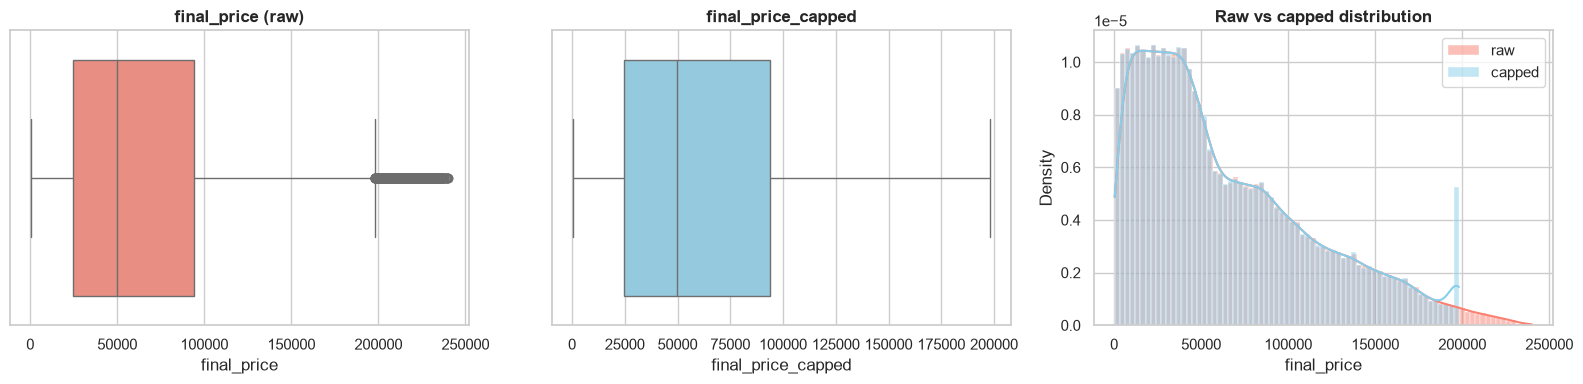

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=df_clean['final_price'], ax=axes[0], color='salmon')
axes[0].set_title('final_price (raw)')
sns.boxplot(x=df_clean['final_price_capped'], ax=axes[1], color='skyblue')
axes[1].set_title('final_price_capped')
sns.histplot(df_clean['final_price'], kde=True, ax=axes[2], color='salmon', label='raw', stat='density', alpha=0.5)
sns.histplot(df_clean['final_price_capped'], kde=True, ax=axes[2], color='skyblue', label='capped', stat='density', alpha=0.5)
axes[2].legend(); axes[2].set_title('Raw vs capped distribution')
plt.tight_layout()
save_fig('capping_demo')
plt.show()

In [45]:
compare = pd.DataFrame({
    'raw':    df_clean['final_price'].describe(),
    'capped': df_clean['final_price_capped'].describe(),
}).round(2)
compare.loc['skew', 'raw']     = round(df_clean['final_price'].skew(), 3)
compare.loc['skew', 'capped']  = round(df_clean['final_price_capped'].skew(), 3)
compare.loc['kurtosis', 'raw']    = round(df_clean['final_price'].kurtosis(), 3)
compare.loc['kurtosis', 'capped'] = round(df_clean['final_price_capped'].kurtosis(), 3)
compare

,raw,capped
count,"100,000.00","100,000.00"
mean,"64,165.72","63,978.84"
std,"49,969.28","49,425.72"
min,357.00,357.00
25%,"24,705.00","24,705.00"
50%,"49,752.39","49,752.39"
75%,"94,046.07","94,046.07"
max,"239,980.00","198,057.68"
skew,0.94,0.88
kurtosis,0.17,-0.06


### Interpretation — Outliers & Capping
*TODO: number of capped rows (~% of dataset); conclusions checked on both raw and capped — conclusions hold since small fraction affected, supporting "outliers are valid purchases."*

## 12. Time-Based Analysis (bonus)
Monthly revenue/orders, weekday order volume, seasonality.

saved -> outputs/figures/monthly_trends.png


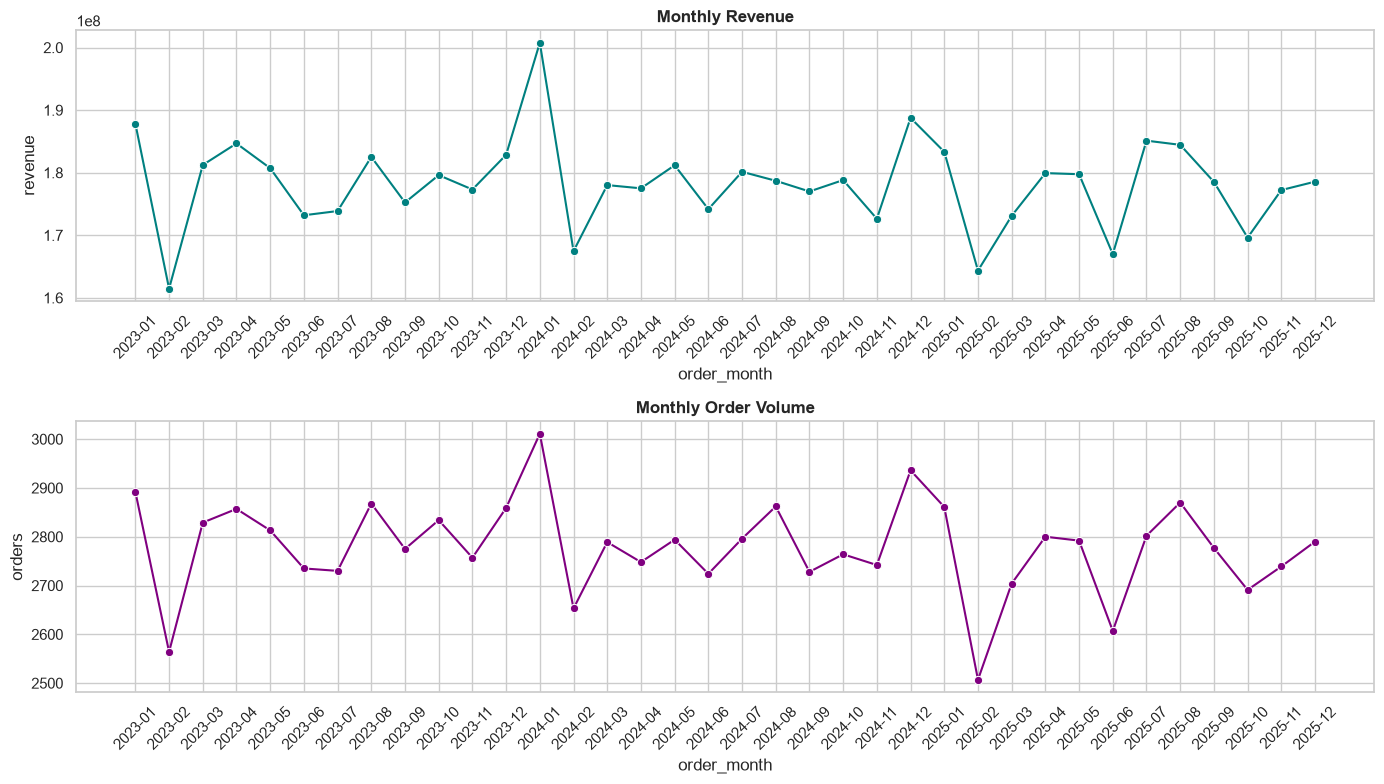

In [46]:
monthly = df_clean.groupby('order_month').agg(
    revenue=('final_price', 'sum'),
    orders=('order_id', 'count'),
    return_rate=('is_return', 'mean')
).reset_index()
monthly['return_rate'] *= 100

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
sns.lineplot(data=monthly, x='order_month', y='revenue', marker='o', ax=axes[0], color='teal')
axes[0].set_title('Monthly Revenue')
axes[0].tick_params(axis='x', rotation=45)
sns.lineplot(data=monthly, x='order_month', y='orders', marker='o', ax=axes[1], color='purple')
axes[1].set_title('Monthly Order Volume')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
save_fig('monthly_trends')
plt.show()

saved -> outputs/figures/weekday_orders.png


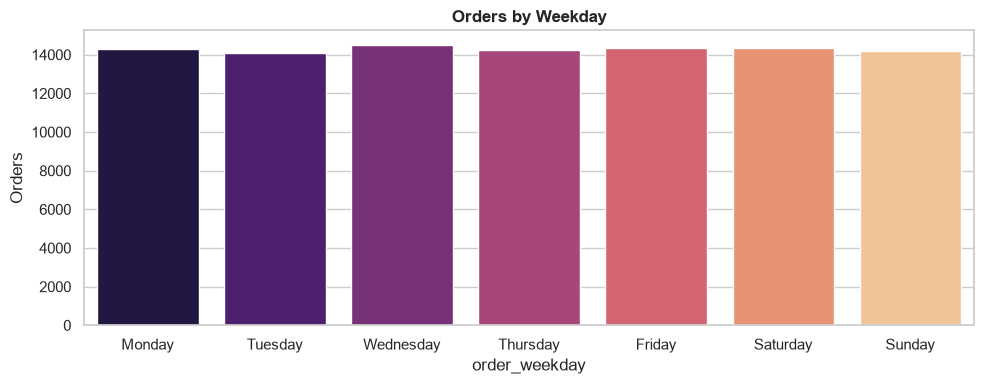

In [47]:
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wd = df_clean['order_weekday'].value_counts().reindex(weekday_order)
plt.figure(figsize=(10, 4))
sns.barplot(x=wd.index, y=wd.values, palette=next_palette())
plt.title('Orders by Weekday')
plt.ylabel('Orders')
plt.tight_layout()
save_fig('weekday_orders')
plt.show()

saved -> outputs/figures/seasonality.png


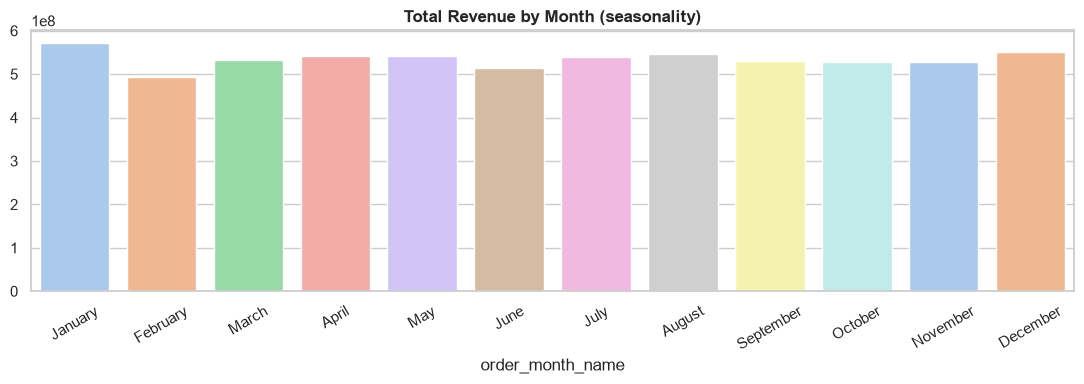

In [48]:
mnth_order = ['January','February','March','April','May','June','July',
              'August','September','October','November','December']
seas = df_clean.groupby('order_month_name')['final_price'].sum().reindex(mnth_order)
plt.figure(figsize=(11, 4))
sns.barplot(x=seas.index, y=seas.values, palette=next_palette())
plt.title('Total Revenue by Month (seasonality)')
plt.xticks(rotation=30)
plt.tight_layout()
save_fig('seasonality')
plt.show()

### Interpretation — Time-Based
*TODO: trends, peak weekday, peak month, early/late-year pattern.*

## 13. Geography — Revenue & Return Rate by City / State (bonus)

In [49]:
state_rev = df_clean.groupby('state').agg(
    revenue=('final_price', 'sum'),
    orders=('order_id', 'count'),
    return_rate=('is_return', 'mean')
).sort_values('revenue', ascending=False)
state_rev['return_rate'] *= 100
state_rev.head(10).round(2)

,revenue,orders,return_rate
state,,,
Maharashtra,"1,283,076,192.61",19952,14.54
Tamil Nadu,"650,624,041.41",9993,15.12
Telangana,"650,427,551.57",10150,14.66
Gujarat,"644,676,956.59",10057,14.79
Karnataka,"640,950,269.83",10047,14.91
West Bengal,"639,976,034.42",9955,14.84
Rajasthan,"639,653,683.71",9920,15.14
Uttar Pradesh,"635,886,934.19",9964,14.63
Delhi,"631,300,673.91",9962,14.95


saved -> outputs/figures/city_revenue_returns.png


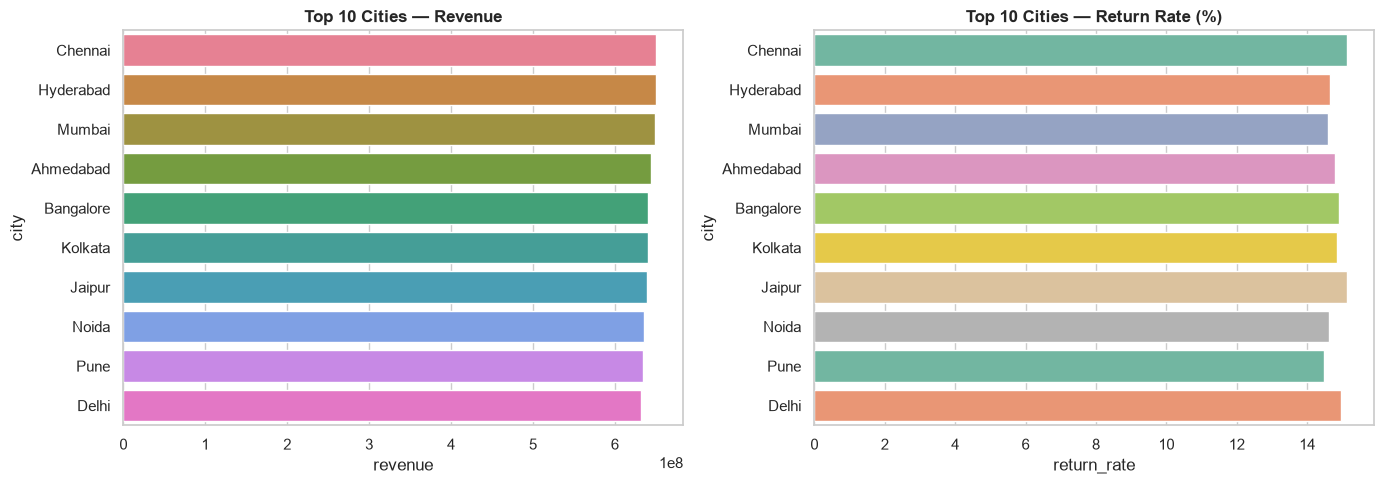

In [50]:
city_rev = df_clean.groupby('city').agg(
    revenue=('final_price', 'sum'),
    return_rate=('is_return', 'mean')
).sort_values('revenue', ascending=False).head(10)
city_rev['return_rate'] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=city_rev['revenue'], y=city_rev.index, ax=axes[0], palette=next_palette())
axes[0].set_title('Top 10 Cities — Revenue')
sns.barplot(x=city_rev['return_rate'], y=city_rev.index, ax=axes[1], palette=next_palette())
axes[1].set_title('Top 10 Cities — Return Rate (%)')
plt.tight_layout()
save_fig('city_revenue_returns')
plt.show()

### Interpretation — Geography
*TODO: top cities/states by revenue; anomalous return-rate cities.*

## 14. Products — Top Subcategories & Return Rates (bonus)

In [51]:
sub_rev = df_clean.groupby('product_subcategory').agg(
    revenue=('final_price', 'sum'),
    orders=('order_id', 'count'),
    return_rate=('is_return', 'mean')
).sort_values('revenue', ascending=False)
sub_rev['return_rate'] *= 100
sub_rev.head(15).round(2)

,revenue,orders,return_rate
product_subcategory,,,
Supplements,"359,895,859.50",5657,15.08
Protein Powder,"359,824,844.17",5668,14.54
Organic Rice,"357,439,669.38",5567,14.46
Shampoo,"356,815,516.89",5578,15.24
Face Cream,"354,036,755.45",5512,13.79
Vitamins,"353,909,548.81",5533,14.87
Snacks,"353,336,813.30",5548,15.23
Pulses,"352,800,723.78",5477,14.92
Perfume,"346,484,223.11",5423,15.25


saved -> outputs/figures/subcategory_revenue_returns.png


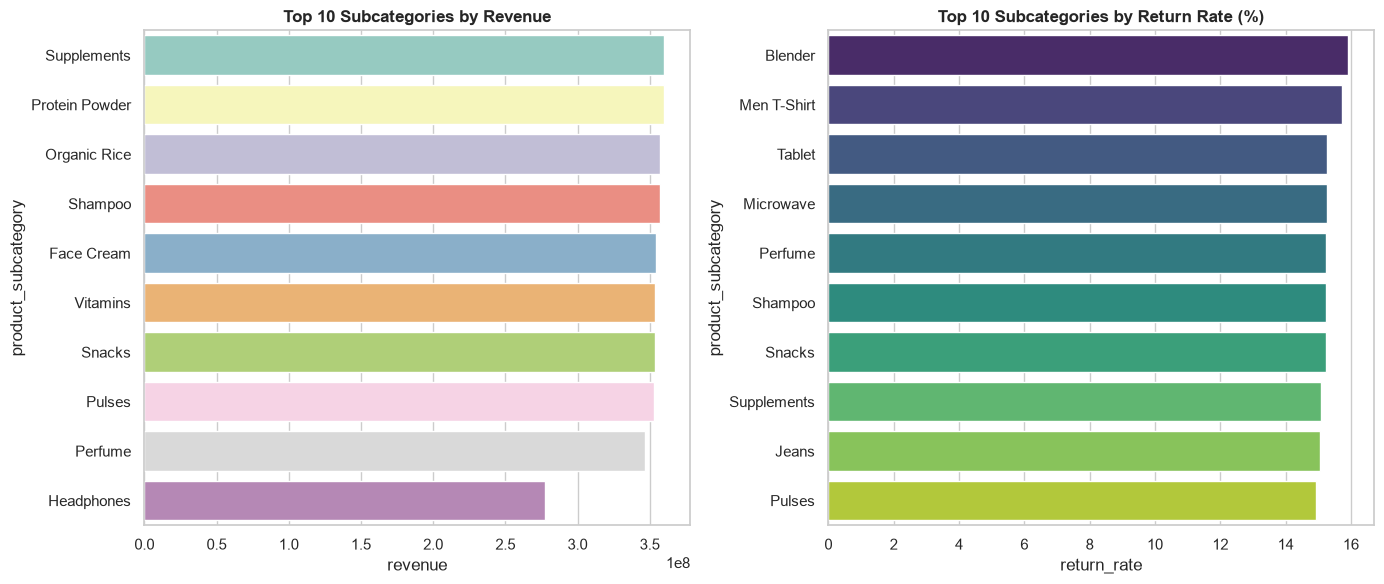

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=sub_rev['revenue'].head(10), y=sub_rev.index[:10],
            ax=axes[0], palette=next_palette())
axes[0].set_title('Top 10 Subcategories by Revenue')

sub_ret = sub_rev.sort_values('return_rate', ascending=False).head(10)
sns.barplot(x=sub_ret['return_rate'], y=sub_ret.index,
            ax=axes[1], palette=next_palette())
axes[1].set_title('Top 10 Subcategories by Return Rate (%)')
plt.tight_layout()
save_fig('subcategory_revenue_returns')
plt.show()

### Interpretation — Products
*TODO: top revenue drivers and highest-return subcategories.*

## 15. Customers — Age × Gender Spending & Discount Band vs Quantity (bonus)

saved -> outputs/figures/age_gender_spend.png


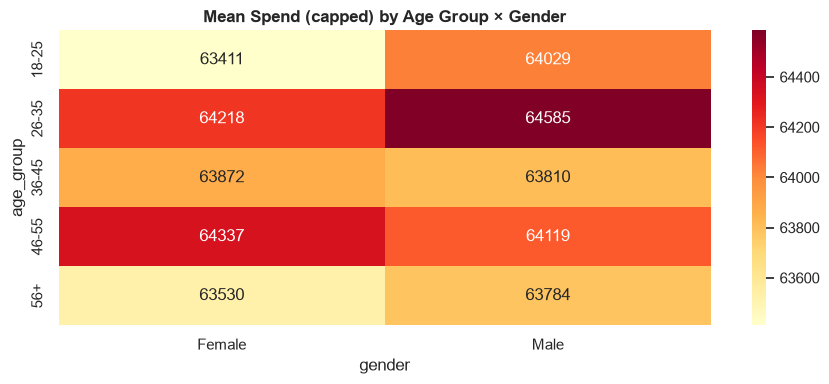

In [53]:
ag = df_clean.pivot_table(values='final_price_capped', index='age_group',
                          columns='gender', aggfunc='mean')
plt.figure(figsize=(9, 4))
sns.heatmap(ag, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Mean Spend (capped) by Age Group × Gender')
plt.tight_layout()
save_fig('age_gender_spend')
plt.show()

In [54]:
dq = df_clean.groupby('discount_bin')['quantity'].agg(['mean', 'median', 'count']).round(2)
dq

,mean,median,count
discount_bin,,,
0%,2.52,3.00,3300
1-10%,2.51,3.00,32127
11-20%,2.50,2.00,32284
21-30%,2.50,3.00,32289


saved -> outputs/figures/discount_band_quantity.png


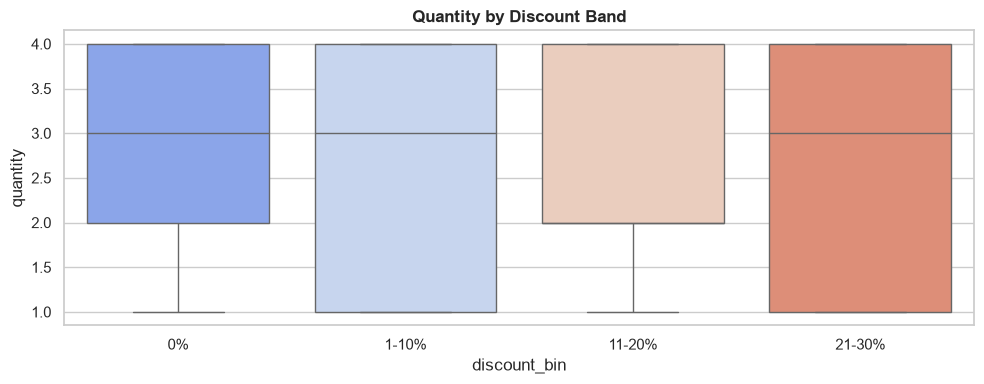

In [55]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='discount_bin', y='quantity', palette=next_palette())
plt.title('Quantity by Discount Band')
plt.tight_layout()
save_fig('discount_band_quantity')
plt.show()

### Interpretation — Customers
*TODO: which age×gender cell spends most; does higher discount correlate with higher quantity.*

## 16. Key Findings & Conclusion

*Placeholders — to be filled once the analysis above has run.*

### Where this data agrees with the project brief
- ...

### Where this data contradicts the brief
- ...

### Business insights
- ...

### Limitations & next steps
- ...